In [20]:
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
%matplotlib inline

In [21]:
df = pd.read_csv("income.csv")
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


# EDA

Text(0, 0.5, 'Income($)')

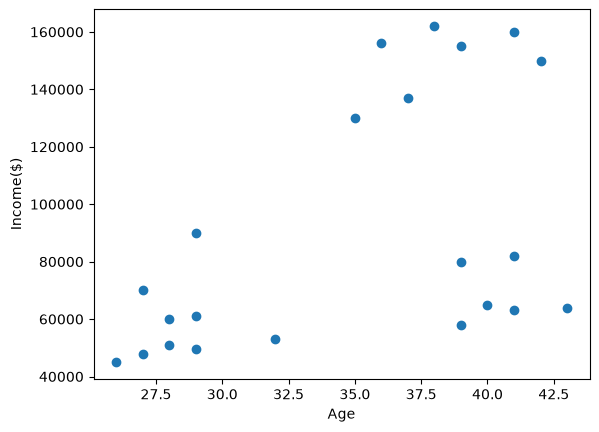

In [22]:
plt.scatter(df.Age,df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income($)')

# KMean

In [23]:
km = KMeans(n_clusters=3, init='k-means++')
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([1, 1, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2],
      dtype=int32)

# Clustering Output Visualization

In [24]:
df['cluster'] = y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,0


In [25]:
df['cluster'] = km.labels_
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,0


In [26]:
df.groupby('cluster').describe().T

cluster                      0             1             2
Age       count       7.000000      4.000000     11.000000
          mean       38.285714     34.000000     32.909091
          std         2.563480      7.023769      6.456850
          min        35.000000     27.000000     26.000000
          25%        36.500000     28.500000     28.000000
          50%        38.000000     34.000000     29.000000
          75%        40.000000     39.500000     39.500000
          max        42.000000     41.000000     43.000000
Income($) count       7.000000      4.000000     11.000000
          mean   150000.000000  80500.000000  56136.363636
          std     12069.244660   8225.975120   7071.389217
          min    130000.000000  70000.000000  45000.000000
          25%    143500.000000  77500.000000  50250.000000
          50%    155000.000000  81000.000000  58000.000000
          75%    158000.000000  84000.000000  62000.000000
          max    162000.000000  90000.000000  65000.000000

In [27]:
km.cluster_centers_

array([[3.82857143e+01, 1.50000000e+05],
       [3.40000000e+01, 8.05000000e+04],
       [3.29090909e+01, 5.61363636e+04]])

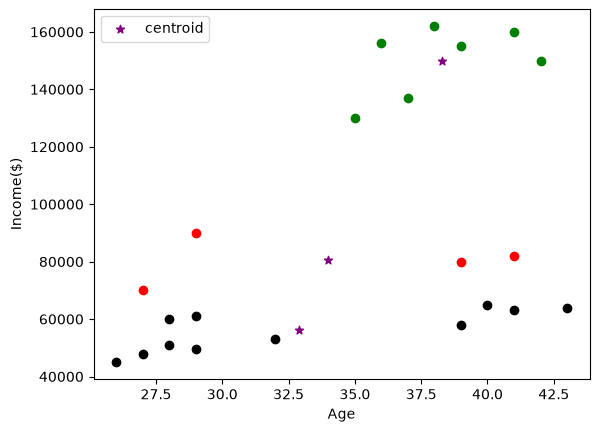

In [28]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income($)')
plt.legend()

# Preprocessing using min max scaler

In [29]:
scaler = MinMaxScaler()
scaler.fit(df[['Income($)']])
df['Income($)'] = scaler.transform(df[['Income($)']])
scaler.fit(df[['Age']])
df['Age'] = scaler.transform(df[['Age']])

df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,2
3,Ismail,0.117647,0.128205,2
4,Kory,0.941176,0.897436,0


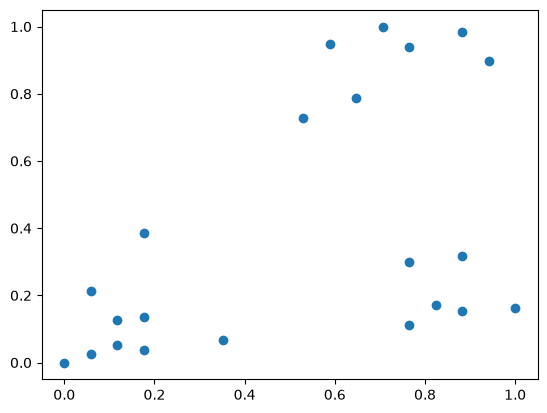

In [30]:
plt.scatter(df.Age, df['Income($)'])

In [31]:
km = KMeans(n_clusters=3, init='k-means++')
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [32]:
df['cluster'] = y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [33]:
km.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

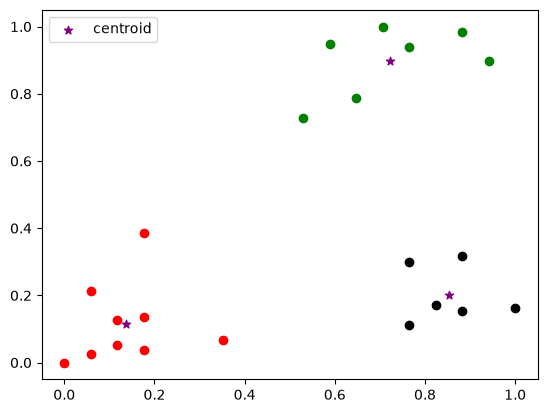

In [34]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.legend()

# Elbow Plot to identify best K

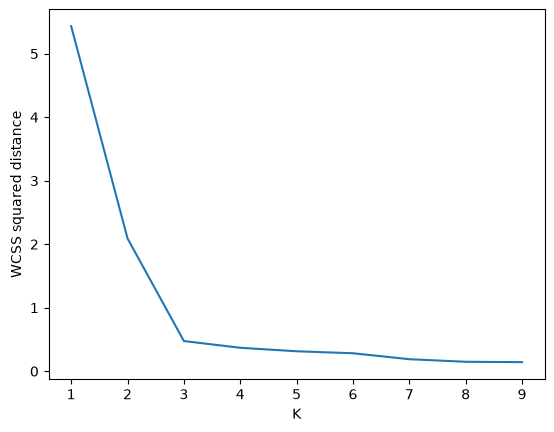

In [35]:
wcss = []
k_rng = range(1,10)
for k in k_rng:
    km = KMeans(n_clusters=k)
    km.fit(df[['Age','Income($)']])
    wcss.append(km.inertia_)

plt.xlabel('K')
plt.ylabel('WCSS squared distance')
plt.plot(k_rng,wcss)

# Select k

In [36]:
for k, w in zip(k_rng, wcss):
    print(k, w)

K_SELECTED = 3 

1 5.434011511988179
2 2.0911363886990784
3 0.4750783498553097
4 0.368773407644059
5 0.3138502783618938
6 0.2824643690681408
7 0.18883868819988073
8 0.1483255465451663
9 0.1425699441447823


# Final KMeans model (selected k)

In [37]:
km_final = KMeans(n_clusters=K_SELECTED, init='k-means++', random_state=42)
df['cluster'] = km_final.fit_predict(df[['Age', 'Income($)']])
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [38]:
km_final.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

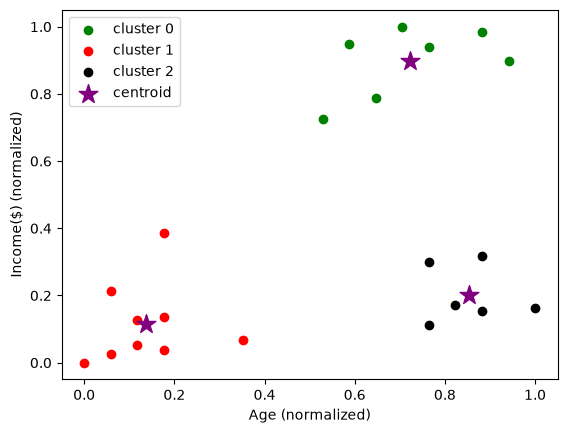

In [39]:
colors = ['green', 'red', 'black', 'orange', 'blue', 'brown', 'cyan', 'magenta', 'gray']
for c in range(K_SELECTED):
    sub = df[df.cluster == c]
    plt.scatter(sub.Age, sub['Income($)'], color=colors[c % len(colors)], label=f'cluster {c}')
plt.scatter(km_final.cluster_centers_[:, 0], km_final.cluster_centers_[:, 1],
            color='purple', marker='*', s=200, label='centroid')
plt.xlabel('Age (normalized)')
plt.ylabel('Income($) (normalized)')
plt.legend()

# Predict new point (same training scaler)

In [40]:
new_point_df = pd.DataFrame([{"Name": "Kevin", "Age": 35, "Income($)": 75000}])
new_point_df.to_csv("new_point.csv", index=False)
new_point_df

,Name,Age,Income($)
0,Kevin,35,75000


In [41]:
df_raw = pd.read_csv("income.csv")
scaler_age = MinMaxScaler().fit(df_raw[['Age']])
scaler_income = MinMaxScaler().fit(df_raw[['Income($)']])

In [42]:
new_point = pd.read_csv("new_point.csv")
new_point_scaled = new_point.copy()
new_point_scaled['Age'] = scaler_age.transform(new_point[['Age']])
new_point_scaled['Income($)'] = scaler_income.transform(new_point[['Income($)']])
new_point_scaled

,Name,Age,Income($)
0,Kevin,0.529412,0.25641


In [43]:
predicted_cluster = km_final.predict(new_point_scaled[['Age', 'Income($)']])[0]
print("Predicted cluster:", predicted_cluster)

Predicted cluster: 2


# Interpret result

In [44]:
print("New point:", new_point.to_dict('records')[0])
print("Predicted cluster:", predicted_cluster)
print("Cluster centroid (normalized Age, Income):", km_final.cluster_centers_[predicted_cluster])
print()
print("Members of this cluster (original, unscaled values):")
df_raw['cluster'] = df['cluster']
print(df_raw[df_raw.cluster == predicted_cluster])

New point: {'Name': 'Kevin', 'Age': 35, 'Income($)': 75000}
Predicted cluster: 2
Cluster centroid (normalized Age, Income): [0.85294118 0.2022792 ]

Members of this cluster (original, unscaled values):
        Name  Age  Income($)  cluster
16    Dipika   40      65000        2
17  Priyanka   41      63000        2
18      Nick   43      64000        2
19      Alia   39      80000        2
20       Sid   41      82000        2
21     Abdul   39      58000        2
